# Parte 4. Simulación Monte Carlo con los parámetros de la Sumativa 1

Se diseñan dos simulaciones que usan solo parámetros estimados en la Sumativa 1:

- **Escenario A (decisión):** casos de enfermedad coronaria a 10 años que podría evitar un programa de control
  de la hipertensión en una cohorte de 1.000 personas.
- **Escenario B (datos sintéticos):** presión sistólica generada con la media, la desviación estándar y la
  asimetría observadas en cada grupo, para evaluar si el IC y la prueba de Welch de la S1 son confiables con
  datos asimétricos como los reales.

Ambas usan 10.000 iteraciones y semilla 42. Al final se evalúa la convergencia y la sensibilidad del
escenario A a sus parámetros de entrada.

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from statsmodels.stats.proportion import proportion_confint

from utils_s2 import (
    SEED, B, RESULTADOS_S1, COLORES,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla, media_acumulada,
)

configurar_graficos()
rng = np.random.default_rng(SEED)
df = cargar_datos()
print(f"Observaciones: {df.shape[0]} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | B = 10,000 | semilla = 42


In [2]:
# Los datos deben reproducir las cifras de la S1
assert round(df["sysBP"].mean(), 2) == RESULTADOS_S1["ic"]["sysbp_media"]["estimacion"]
assert round(df["TenYearCHD"].mean() * 100, 2) == RESULTADOS_S1["ic"]["prop_chd_%"]["estimacion"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


## 4.1 Parámetros de entrada

Todos provienen de la S1: la prevalencia de hipertensión (Tabla 3), las tasas de CHD por grupo con su
intervalo de Wilson (Figura 4) y la presión sistólica por grupo (Tabla 4 y sección 4.1). Se recalculan desde
los datos para usar todos los decimales.

In [3]:
def proporcion(eventos, n):
    inf, sup = proportion_confint(eventos, n, alpha=0.05, method="wilson")
    return {"estimacion": eventos / n, "ic_inf": inf, "ic_sup": sup, "n": n}

hip = df["prevalentHyp"] == 1
PARAM = {
    "Prevalencia de hipertensión": proporcion(int(hip.sum()), len(df)),
    "Tasa de CHD con hipertensión": proporcion(int(df.loc[hip, "TenYearCHD"].sum()), int(hip.sum())),
    "Tasa de CHD sin hipertensión": proporcion(int(df.loc[~hip, "TenYearCHD"].sum()), int((~hip).sum())),
}
PREV = PARAM["Prevalencia de hipertensión"]["estimacion"]
P_HT = PARAM["Tasa de CHD con hipertensión"]["estimacion"]
P_NO = PARAM["Tasa de CHD sin hipertensión"]["estimacion"]

pas = df.groupby("TenYearCHD")["sysBP"].agg(n="count", media="mean", de="std", asimetria="skew")
pas.index = ["Sin CHD", "Con CHD"]

tabla_param = pd.DataFrame(PARAM).T
tabla_param[["estimacion", "ic_inf", "ic_sup"]] *= 100
display(tabla_param.round(2))
display(pas.round(2))

,estimacion,ic_inf,ic_sup,n
Prevalencia de hipertensión,31.0600,29.6900,32.4700,"4,240.0000"
Tasa de CHD con hipertensión,24.6800,22.4200,27.0800,"1,317.0000"
Tasa de CHD sin hipertensión,10.9100,9.8300,12.1000,"2,923.0000"


,n,media,de,asimetria
Sin CHD,3596,130.3400,20.4500,1.0600
Con CHD,644,143.6200,26.6900,1.0000


## 4.2 Escenario A: programa de control de la hipertensión

**Justificación.** En la S1 la hipertensión fue uno de los factores con asociación más clara con la CHD
(24,7 % frente a 10,9 %) y es modificable. Se simula una cohorte de 1.000 personas con las características de
la muestra y un programa que controla una fracción *f* de los hipertensos (20 %, 40 % y 60 %). Los controlados
pasan a tener la tasa de CHD de los no hipertensos.

**Modelo por iteración.**

1. Hipertensos: H ~ Binomial(1.000; prevalencia).
2. Controlados por el programa: C ~ Binomial(H; *f*).
3. Casos de CHD en cada grupo con su tasa. Para los controlados se usa el mismo azar en ambos escenarios
   (números aleatorios comunes): quien enfermaría con la tasa baja también enferma con la alta, y los casos
   evitados son los que solo aparecen con la tasa alta.

**Supuesto clave.** Tratar la diferencia de tasas como efecto causal del control es optimista: la asociación de
la S1 es bivariada y en parte se explica por la edad. Por eso los casos evitados se leen como un **límite
superior** del beneficio.

In [4]:
N_COHORTE = 1_000
FRACCIONES = [0.2, 0.4, 0.6]


def simular_programa(f, prev=PREV, p_ht=P_HT, p_no=P_NO, n=N_COHORTE, b=B, rng=rng):
    """Casos de CHD sin programa, con programa y evitados, en b cohortes simuladas."""
    h = rng.binomial(n, prev, b)
    c = rng.binomial(h, f)
    casos_ctrl_tasa_baja = rng.binomial(c, p_no)
    evitados = rng.binomial(c - casos_ctrl_tasa_baja, (p_ht - p_no) / (1 - p_no))
    resto = rng.binomial(h - c, p_ht) + rng.binomial(n - h, p_no)
    sin_programa = resto + casos_ctrl_tasa_baja + evitados
    return sin_programa, sin_programa - evitados, evitados


sim = {f: simular_programa(f) for f in FRACCIONES}

filas = []
for f, (sin_prog, con_prog, evit) in sim.items():
    filas.append({
        "Hipertensos controlados (%)": int(f * 100),
        "Casos sin programa (media)": sin_prog.mean(),
        "Casos con programa (media)": con_prog.mean(),
        "Casos evitados (media)": evit.mean(),
        "Evitados IC95 inf": np.percentile(evit, 2.5),
        "Evitados IC95 sup": np.percentile(evit, 97.5),
        "Reducción relativa (%)": evit.mean() / sin_prog.mean() * 100,
        "P(evitados ≥ 10)": (evit >= 10).mean(),
    })
tabla_a = pd.DataFrame(filas).set_index("Hipertensos controlados (%)")
guardar_tabla(tabla_a.round(3), "p4_escenarios_programa")

,Casos sin programa (media),Casos con programa (media),Casos evitados (media),Evitados IC95 inf,Evitados IC95 sup,Reducción relativa (%),P(evitados ≥ 10)
Hipertensos controlados (%),,,,,,,
20,151.7360,143.2060,8.5300,3.0000,15.0000,5.6220,0.3490
40,151.7220,134.6440,17.0790,10.0000,26.0000,11.2570,0.9790
60,151.8970,126.2260,25.6710,16.0000,36.0000,16.9000,1.0000


In [5]:
sin_prog = sim[0.4][0]
tasa_sim = sin_prog.mean() / N_COHORTE * 100
ic_tasa = np.percentile(sin_prog, [2.5, 97.5]) / N_COHORTE * 100
print(f"Tasa de CHD simulada sin programa: {tasa_sim:.2f} % (95 % de las cohortes entre {ic_tasa[0]:.1f} % y {ic_tasa[1]:.1f} %)")
print(f"Tasa observada en la S1: {RESULTADOS_S1['ic']['prop_chd_%']['estimacion']:.2f} % "
      f"[{RESULTADOS_S1['ic']['prop_chd_%']['ic'][0]}; {RESULTADOS_S1['ic']['prop_chd_%']['ic'][1]}]")

Tasa de CHD simulada sin programa: 15.17 % (95 % de las cohortes entre 13.0 % y 17.4 %)
Tasa observada en la S1: 15.19 % [14.14; 16.3]


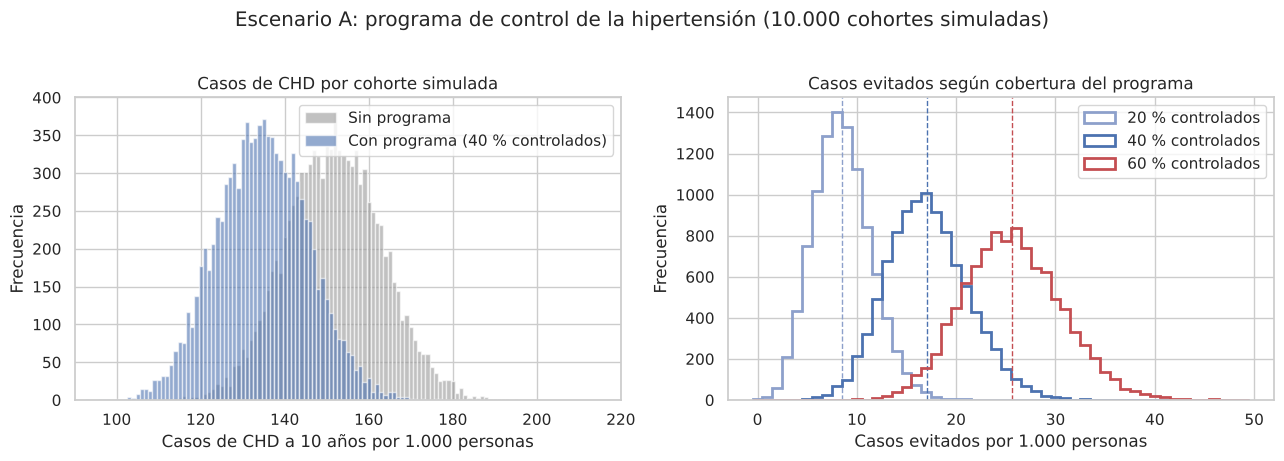

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colores_f = {0.2: COLORES["caja"], 0.4: COLORES["principal"], 0.6: COLORES["riesgo"]}

ax = axes[0]
bordes = np.arange(79.5, 230.5, 1)
ax.hist(sim[0.4][0], bins=bordes, color="0.6", alpha=0.6, label="Sin programa")
ax.hist(sim[0.4][1], bins=bordes, color=COLORES["principal"], alpha=0.6, label="Con programa (40 % controlados)")
ax.set(xlim=(90, 220), xlabel="Casos de CHD a 10 años por 1.000 personas", ylabel="Frecuencia",
       title="Casos de CHD por cohorte simulada")
ax.legend()

ax = axes[1]
bordes = np.arange(-0.5, 50.5, 1)
for f in FRACCIONES:
    evit = sim[f][2]
    ax.hist(evit, bins=bordes, histtype="step", lw=2, color=colores_f[f], label=f"{int(f*100)} % controlados")
    ax.axvline(evit.mean(), color=colores_f[f], ls="--", lw=1)
ax.set(xlabel="Casos evitados por 1.000 personas", ylabel="Frecuencia",
       title="Casos evitados según cobertura del programa")
ax.legend()
plt.suptitle(f"Escenario A: programa de control de la hipertensión ({B:,} cohortes simuladas)".replace(",", "."), y=1.02)
guardar_figura("p4_fig1_escenario_programa")

## 4.3 Escenario A con incertidumbre de los parámetros

La simulación anterior fija los parámetros en su estimación puntual. Para propagar también la incertidumbre
de la S1, en cada iteración se extraen la prevalencia y las dos tasas de una normal centrada en su estimación,
con su error estándar de la S1.

In [7]:
def sortear_parametros(b=B, rng=rng):
    def normal(clave):
        p, n = PARAM[clave]["estimacion"], PARAM[clave]["n"]
        return np.clip(rng.normal(p, np.sqrt(p * (1 - p) / n), b), 0, 1)
    prev = normal("Prevalencia de hipertensión")
    p_ht = normal("Tasa de CHD con hipertensión")
    p_no = np.minimum(normal("Tasa de CHD sin hipertensión"), p_ht)
    return prev, p_ht, p_no


prev_s, p_ht_s, p_no_s = sortear_parametros()
_, _, evit_incert = simular_programa(0.4, prev=prev_s, p_ht=p_ht_s, p_no=p_no_s)
evit_fijo = sim[0.4][2]
tabla_incert = pd.DataFrame({
    "Media": [evit_fijo.mean(), evit_incert.mean()],
    "DE": [evit_fijo.std(ddof=1), evit_incert.std(ddof=1)],
    "IC95 inf": [np.percentile(evit_fijo, 2.5), np.percentile(evit_incert, 2.5)],
    "IC95 sup": [np.percentile(evit_fijo, 97.5), np.percentile(evit_incert, 97.5)],
}, index=["Parámetros fijos", "Con incertidumbre de la S1"])
tabla_incert.index.name = "Casos evitados (40 % controlados)"
guardar_tabla(tabla_incert.round(2), "p4_incertidumbre_parametros")

,Media,DE,IC95 inf,IC95 sup
Casos evitados (40 % controlados),,,,
Parámetros fijos,17.0800,4.0900,10.0000,26.0000
Con incertidumbre de la S1,17.0200,4.4500,9.0000,26.0000


## 4.4 Escenario B: datos sintéticos de presión sistólica

**Justificación.** En la S1 la presión sistólica no es normal (asimetría ≈ 1 en ambos grupos) y la prueba de
Welch se justificó por el Teorema Central del Límite. Aquí se verifica ese supuesto: se generan muestras
sintéticas con la misma media, desviación estándar y asimetría de cada grupo, y se mide con qué frecuencia el
IC 95 % de Welch contiene la diferencia verdadera (cobertura) y con qué frecuencia la prueba la detecta
(potencia). Se repite con tamaños muestrales menores, manteniendo la proporción de casos con CHD (15,2 %).

**Generador.** Lognormal desplazada de tres parámetros, ajustada por momentos a la media, la DE y la asimetría
de cada grupo.

In [8]:
def lognormal_desplazada(media, de, asimetria):
    """Parámetros (sigma, escala, desplazamiento) con la media, DE y asimetría pedidas."""
    w = brentq(lambda w: (w + 2) * np.sqrt(w - 1) - asimetria, 1 + 1e-12, 50)
    sigma = np.sqrt(np.log(w))
    escala = de / np.sqrt((w - 1) * w)
    return sigma, escala, media - escala * np.sqrt(w)


GEN = {g: lognormal_desplazada(*pas.loc[g, ["media", "de", "asimetria"]]) for g in pas.index}


def generar(grupo, size, rng=rng):
    sigma, escala, desplaz = GEN[grupo]
    return desplaz + escala * np.exp(sigma * rng.standard_normal(size))


control = pd.DataFrame({g: (lambda x: [x.mean(), x.std(ddof=1), stats.skew(x)])(generar(g, 1_000_000))
                        for g in pas.index}, index=["media", "de", "asimetria"]).T
display(pd.concat({"Observado (S1)": pas[["media", "de", "asimetria"]], "Sintético": control}, axis=1).round(2))

Observado (S1)                   Sintético                  
                 media      de asimetria     media      de asimetria
Sin CHD       130.3400 20.4500    1.0600  130.3600 20.4400    1.0500
Con CHD       143.6200 26.6900    1.0000  143.6300 26.7000    1.0100

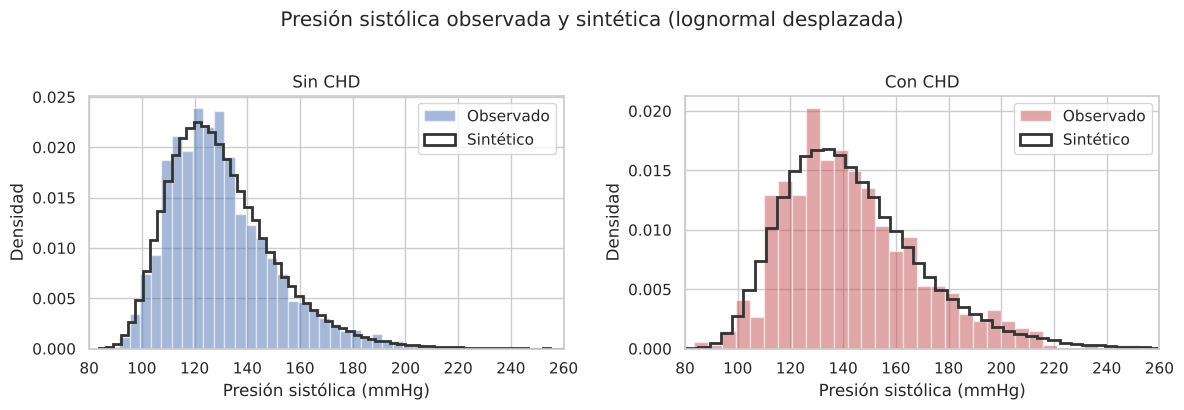

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g, color in zip(axes, pas.index, [COLORES["principal"], COLORES["riesgo"]]):
    obs = df.loc[df["TenYearCHD"] == (g == "Con CHD"), "sysBP"]
    ax.hist(obs, bins=40, density=True, alpha=0.5, color=color, label="Observado")
    ax.hist(generar(g, 200_000), bins=80, density=True, histtype="step", lw=2, color="0.2", label="Sintético")
    ax.set(xlim=(80, 260), xlabel="Presión sistólica (mmHg)", ylabel="Densidad", title=g)
    ax.legend()
plt.suptitle("Presión sistólica observada y sintética (lognormal desplazada)", y=1.02)
guardar_figura("p4_fig2_sintetico_vs_observado")

In [10]:
DIF_REAL = pas.loc["Con CHD", "media"] - pas.loc["Sin CHD", "media"]


def welch_simulado(n1, n0, b=B, bloque=500, rng=rng):
    """Cobertura del IC 95 % de Welch y rechazo de H0 en b pares de muestras sintéticas."""
    cubre, rechaza = [], []
    for _ in range(b // bloque):
        x1 = generar("Con CHD", (bloque, n1), rng)
        x0 = generar("Sin CHD", (bloque, n0), rng)
        v1, v0 = x1.var(axis=1, ddof=1) / n1, x0.var(axis=1, ddof=1) / n0
        ee = np.sqrt(v1 + v0)
        gl = (v1 + v0) ** 2 / (v1 ** 2 / (n1 - 1) + v0 ** 2 / (n0 - 1))
        t_crit = stats.t.ppf(0.975, gl)
        dif = x1.mean(axis=1) - x0.mean(axis=1)
        cubre.append(np.abs(dif - DIF_REAL) <= t_crit * ee)
        rechaza.append(np.abs(dif) / ee > t_crit)
    return np.concatenate(cubre), np.concatenate(rechaza)


TAMANOS = [(644, 3596), (150, 838), (50, 279), (20, 112), (10, 56), (5, 28)]
res_b, filas = {}, []
for n1, n0 in TAMANOS:
    cubre, rechaza = welch_simulado(n1, n0)
    res_b[(n1, n0)] = cubre
    ee_mc = np.sqrt(cubre.mean() * (1 - cubre.mean()) / B)
    filas.append({"n con CHD": n1, "n sin CHD": n0, "n total": n1 + n0,
                  "Cobertura IC 95 % (%)": cubre.mean() * 100, "EE Monte Carlo (pp)": ee_mc * 100,
                  "Potencia (%)": rechaza.mean() * 100})
tabla_b = pd.DataFrame(filas).set_index("n total")
guardar_tabla(tabla_b.round(2), "p4_cobertura_potencia")

,n con CHD,n sin CHD,Cobertura IC 95 % (%),EE Monte Carlo (pp),Potencia (%)
n total,,,,,
4240,644,3596,95.0800,0.2200,100.0000
988,150,838,94.7600,0.2200,100.0000
329,50,279,94.6400,0.2300,93.7200
132,20,112,94.7300,0.2200,52.4300
66,10,56,93.6000,0.2400,23.0800
33,5,28,92.6900,0.2600,9.7600


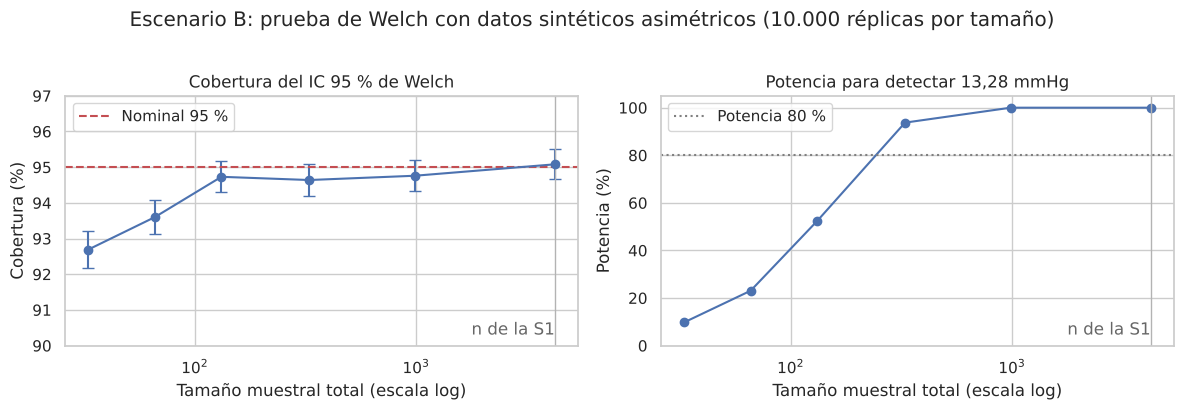

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ee = tabla_b["EE Monte Carlo (pp)"]
ax.errorbar(tabla_b.index, tabla_b["Cobertura IC 95 % (%)"], yerr=1.96 * ee, fmt="o-",
            color=COLORES["principal"], capsize=4)
ax.axhline(95, color=COLORES["riesgo"], ls="--", label="Nominal 95 %")
ax.set(xscale="log", ylim=(90, 97), xlabel="Tamaño muestral total (escala log)", ylabel="Cobertura (%)",
       title="Cobertura del IC 95 % de Welch")
ax.legend()
ax = axes[1]
ax.plot(tabla_b.index, tabla_b["Potencia (%)"], "o-", color=COLORES["principal"])
ax.axhline(80, color="0.5", ls=":", label="Potencia 80 %")
ax.set(xscale="log", ylim=(0, 105), xlabel="Tamaño muestral total (escala log)", ylabel="Potencia (%)",
       title=f"Potencia para detectar {DIF_REAL:.2f} mmHg".replace(".", ","))
ax.legend()
for a in axes:
    a.axvline(4240, color="0.7", lw=1)
    a.annotate("n de la S1", (4240, a.get_ylim()[0]), xytext=(-60, 8), textcoords="offset points", color="0.4")
plt.suptitle(f"Escenario B: prueba de Welch con datos sintéticos asimétricos ({B:,} réplicas por tamaño)".replace(",", "."), y=1.02)
guardar_figura("p4_fig3_cobertura_potencia")

## 4.5 Convergencia

Se grafica la media acumulada de los casos evitados (escenario A, 40 % controlados) y de la cobertura del
IC (escenario B, n de la S1) con su banda ±1,96 · EE Monte Carlo. La simulación converge si la media se
estabiliza y la banda se estrecha a un ancho despreciable para la interpretación.

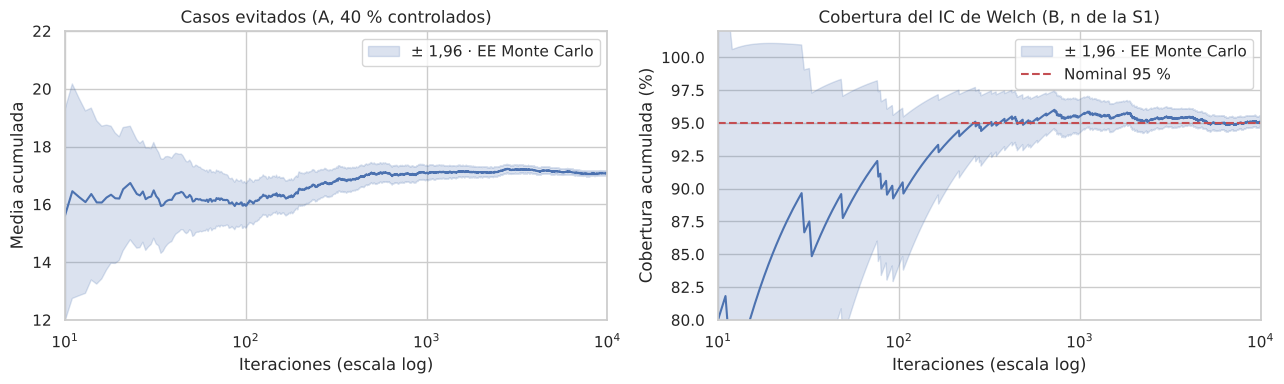

,Evitados: media,Evitados: EE,Cobertura: media (%),Cobertura: EE (pp)
Iteraciones,,,,
100,15.9500,0.3950,90.0000,3.0150
1000,17.0880,0.1300,95.5000,0.6560
5000,17.1350,0.0580,95.1200,0.3050
10000,17.0790,0.0410,95.0800,0.2160


In [12]:
conv_a = media_acumulada(sim[0.4][2])
conv_b = media_acumulada(res_b[(644, 3596)].astype(float) * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, conv, titulo, ylab, ref in [
    (axes[0], conv_a, "Casos evitados (A, 40 % controlados)", "Media acumulada", None),
    (axes[1], conv_b, "Cobertura del IC de Welch (B, n de la S1)", "Cobertura acumulada (%)", 95),
]:
    ax.plot(conv["iteracion"], conv["media"], color=COLORES["principal"])
    ax.fill_between(conv["iteracion"], conv["media"] - 1.96 * conv["ee"], conv["media"] + 1.96 * conv["ee"],
                    color=COLORES["principal"], alpha=0.2, label="± 1,96 · EE Monte Carlo")
    if ref is not None:
        ax.axhline(ref, color=COLORES["riesgo"], ls="--", label="Nominal 95 %")
        ax.set_ylim(80, 102)
    else:
        ax.set_ylim(12, 22)
    ax.set(xscale="log", xlim=(10, B), xlabel="Iteraciones (escala log)", ylabel=ylab, title=titulo)
    ax.legend()
guardar_figura("p4_fig4_convergencia")

hitos = [100, 1_000, 5_000, 10_000]
tabla_conv = pd.DataFrame({
    "Evitados: media": conv_a.set_index("iteracion").loc[hitos, "media"],
    "Evitados: EE": conv_a.set_index("iteracion").loc[hitos, "ee"],
    "Cobertura: media (%)": conv_b.set_index("iteracion").loc[hitos, "media"],
    "Cobertura: EE (pp)": conv_b.set_index("iteracion").loc[hitos, "ee"],
})
tabla_conv.index.name = "Iteraciones"
guardar_tabla(tabla_conv.round(3), "p4_convergencia")

## 4.6 Análisis de sensibilidad

Se varía cada parámetro de entrada del escenario A entre los límites de su IC 95 % de la S1, dejando los
demás en su estimación, y se registra el cambio en los casos evitados con 40 % de cobertura (gráfico de
tornado). La cobertura del programa no se incluye porque es una decisión, no un parámetro estimado; su efecto
ya se muestra en la sección 4.2.

In [13]:
claves = {"Prevalencia de hipertensión": "prev", "Tasa de CHD con hipertensión": "p_ht",
          "Tasa de CHD sin hipertensión": "p_no"}
base = sim[0.4][2].mean()
filas = []
for nombre, arg in claves.items():
    fila = {"Parámetro": nombre}
    for limite in ["ic_inf", "ic_sup"]:
        valor = PARAM[nombre][limite]
        fila[f"Valor {limite[-3:]} (%)"] = valor * 100
        fila[f"Evitados con {limite[-3:]}"] = simular_programa(0.4, **{arg: valor})[2].mean()
    filas.append(fila)
tabla_sens = pd.DataFrame(filas).set_index("Parámetro")
tabla_sens["Rango (casos)"] = (tabla_sens["Evitados con sup"] - tabla_sens["Evitados con inf"]).abs()
tabla_sens = tabla_sens.sort_values("Rango (casos)")
guardar_tabla(tabla_sens.round(2), "p4_sensibilidad")

,Valor inf (%),Evitados con inf,Valor sup (%),Evitados con sup,Rango (casos)
Parámetro,,,,,
Prevalencia de hipertensión,29.6900,16.3800,32.4700,17.8800,1.4900
Tasa de CHD sin hipertensión,9.8300,18.4800,12.1000,15.6200,2.8600
Tasa de CHD con hipertensión,22.4200,14.3200,27.0800,20.0900,5.7600


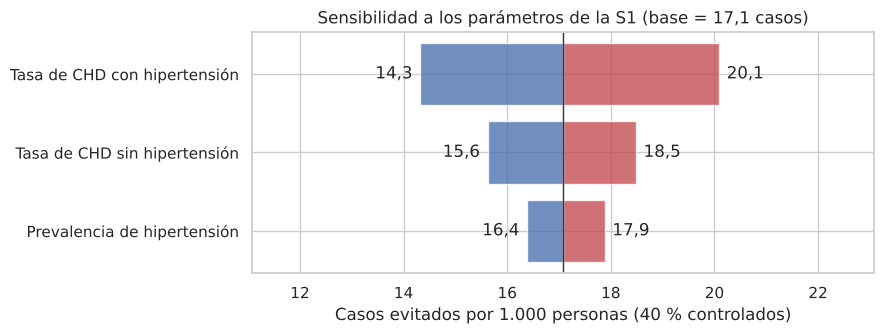

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(tabla_sens))
for i, (nombre, fila) in enumerate(tabla_sens.iterrows()):
    lo, hi = sorted([fila["Evitados con inf"], fila["Evitados con sup"]])
    ax.barh(i, hi - base, left=base, color=COLORES["riesgo"], alpha=0.8)
    ax.barh(i, lo - base, left=base, color=COLORES["principal"], alpha=0.8)
    ax.text(hi + 0.15, i, f"{hi:.1f}".replace(".", ","), va="center")
    ax.text(lo - 0.15, i, f"{lo:.1f}".replace(".", ","), va="center", ha="right")
ax.axvline(base, color="0.2", lw=1)
ax.set_yticks(y, tabla_sens.index)
ax.set(xlabel="Casos evitados por 1.000 personas (40 % controlados)",
       title=f"Sensibilidad a los parámetros de la S1 (base = {base:.1f} casos)".replace(".", ","))
ax.set_xlim(base - 6, base + 6)
guardar_figura("p4_fig5_tornado")

## 4.7 Interpretación

**Escenario A.** El modelo reproduce el fenómeno observado: sin programa se esperan 151,7 casos por 1.000
personas (15,17 %), prácticamente igual a la tasa de la S1 (15,19 % [14,14; 16,30]). El rango entre cohortes
(13,0 % a 17,4 %) es más amplio que el IC de la S1 porque describe cohortes de 1.000 personas y no la media
poblacional.

Los casos evitados crecen de forma lineal con la cobertura: 8,5 [3; 15] con 20 % de hipertensos controlados,
17,1 [10; 26] con 40 % y 25,7 [16; 36] con 60 %, es decir, reducciones de 5,6 %, 11,3 % y 16,9 % de los casos.
Equivale a controlar unos 7 hipertensos por cada caso evitado (1 / (24,7 % − 10,9 %)). Con 20 % de cobertura
el beneficio es incierto (solo 35 % de las cohortes evita 10 casos o más); desde 40 % lo logra el 98 %.
Agregar la incertidumbre de los parámetros de la S1 casi no cambia el resultado (DE de 4,1 a 4,5 casos): con
más de 4.000 observaciones, la variabilidad dominante es la del azar entre personas y no la de la estimación.
Estas cifras son un límite superior, porque suponen que toda la diferencia de tasas se debe a la hipertensión.

**Escenario B.** Los datos sintéticos reproducen la media, la DE y la asimetría de la presión sistólica en
ambos grupos. Con el tamaño de la S1, el IC 95 % de Welch cubre la diferencia verdadera el 95,1 % de las veces
(EE 0,2 pp) y la prueba la detecta siempre, por lo que la conclusión de la S1 (13,28 mmHg, p < 0,001) no se ve
afectada por la falta de normalidad. La cobertura cae a 93,6 % con 66 personas y a 92,7 % con 33, y la potencia
baja de 94 % (n = 329) a 52 % (n = 132): el TCL respalda el análisis de la muestra completa, pero no el de
subgrupos pequeños como diabetes (n = 109) o ACV previo (n = 25).

**Convergencia.** La media de casos evitados pasa de 15,95 con 100 iteraciones a 17,09 con 1.000 y 17,08 con
10.000, con un EE Monte Carlo final de 0,04 casos; la cobertura termina en 95,08 % con EE de 0,22 pp. Con
10.000 iteraciones el error de simulación es despreciable frente a la incertidumbre del fenómeno.

**Sensibilidad.** El resultado depende sobre todo de la tasa de CHD de los hipertensos (14,3 a 20,1 casos
dentro de su IC), luego de la tasa de los no hipertensos (15,6 a 18,5) y poco de la prevalencia (16,4 a 17,9).
Como los casos evitados son proporcionales a la diferencia entre ambas tasas, la recomendación para la S3 es
estimar el efecto de la hipertensión ajustado por edad y otros factores con regresión logística: es la entrada
más influyente y la que hoy descansa en el supuesto causal más fuerte.